# Do people who try more features in their first week come back?

GitHub is a SaaS product with many features: repositories, pushing code, pull
requests, issues, stars, forks. This notebook asks a classic onboarding question
on real usage data: do new accounts that try more of the product in their first
week come back more often, and what should onboarding nudge people towards?

**Data.** Every public GitHub event from [GH Archive](https://www.gharchive.org),
June to September 2025. `src/build.py` turns it into one row per new account:

- **New account:** registered between 2 and 29 June 2025 and did something public
  within two weeks. GH Archive has no sign-up date, but GitHub hands out account ids
  in order, so each sign-up week is a known range of ids.
- **Week one:** the 7 days starting with the account's first public action.
- **Features:** the 11 product areas an event belongs to, for example pushing
  code, creating a repository or branch, opening a pull request, starring.
- **Came back:** any public activity on days 28 to 55, the account's second month.

**One caveat.** GH Archive only sees public activity. Someone who keeps working in
private repositories looks like they never came back, so every rate here is a
floor, not the true number.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "img"

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c9c8c3"
plt.rcParams.update({
    "font.family": "Helvetica Neue", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#e6e5e1", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e6e5e1", "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "xtick.major.size": 0, "ytick.major.size": 0,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
})


def title(ax, headline, sub):
    ax.set_title(f"{headline}\n", loc="left", fontsize=14, fontweight="bold", pad=22)
    ax.text(0, 1.05, sub, transform=ax.transAxes, fontsize=10.5, color="#52514e")


def pct_axis(ax, top):
    ax.set_ylim(0, top)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")

## The data: one row per new account

In [2]:
accounts = pd.read_parquet(ROOT / "data" / "newcomers.parquet")
print(f"{len(accounts):,} new accounts")
accounts.sample(3, random_state=7)[
    ["signup_week", "first_action", "active_days_week1", "features_week1", "feature_list", "came_back"]]

627,777 new accounts


,signup_week,first_action,active_days_week1,features_week1,feature_list,came_back
550240,2025-06-09,2025-06-15,2,3,"[Branches and repos, Pull requests, Push code]",False
159346,2025-06-23,2025-06-27,1,1,[Stars],False
234396,2025-06-09,2025-06-11,1,1,[Branches and repos],False


A few accounts are not people. GitHub marks its own bots with a login ending in
`[bot]`, and a handful of accounts post hundreds of events a day, which is a script,
not a person. The busiest 0.1% of real accounts stay under 200 events a day, so that
is the cut-off.

In [3]:
is_bot = accounts["declared_bot"] | (accounts["busiest_day_week1"] > 200)
print(f"declared bots: {accounts['declared_bot'].sum():,}")
print(f"more than 200 events on one day: {(~accounts['declared_bot'] & is_bot).sum():,}")
people = accounts[~is_bot].copy()
print(f"people: {len(people):,}")

declared bots: 714
more than 200 events on one day: 447
people: 626,616


## 1. How many new accounts come back in their second month?

In [4]:
came_back = people["came_back"].mean()
print(f"{people['came_back'].sum():,} of {len(people):,} came back: {came_back:.1%}")

79,032 of 626,616 came back: 12.6%


In [5]:
by_week = (people.groupby("signup_week")["came_back"]
           .agg(accounts="size", came_back="mean")
           .assign(came_back=lambda d: (d["came_back"] * 100).round(1)))
by_week

,accounts,came_back
signup_week,,
2025-06-02,160539,11.9
2025-06-09,154894,12.4
2025-06-16,158398,12.7
2025-06-23,152785,13.5


About one new account in eight is active again a month later, and every sign-up week
looks the same, so the four weeks can be pooled.

## 2. Do people who try more features in week one come back more often?

In [6]:
people["features"] = pd.cut(people["features_week1"], [-1, 1, 2, 3, 99],
                            labels=["0-1", "2", "3", "4+"])
by_features = (people.groupby("features", observed=True)["came_back"]
               .agg(accounts="size", came_back="mean"))
by_features["share_of_accounts"] = (by_features["accounts"] / len(people) * 100).round(1)
by_features["came_back"] = (by_features["came_back"] * 100).round(1)
by_features

,accounts,came_back,share_of_accounts
features,,,
0-1,356012,9.1,56.8
2,226816,15.9,36.2
3,33675,23.1,5.4
4+,10113,29.4,1.6


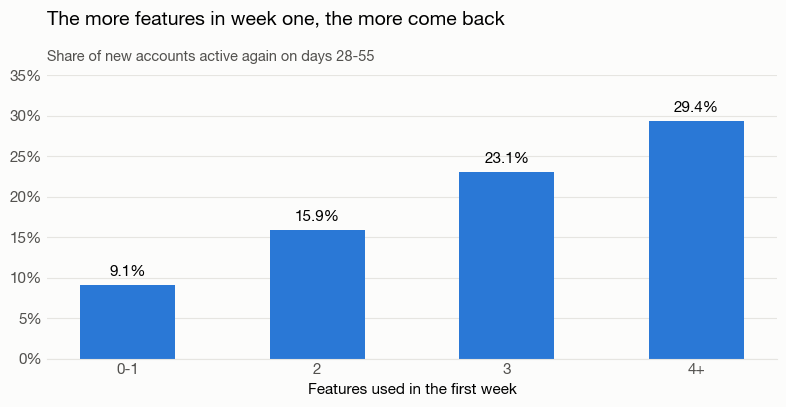

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(by_features.index.astype(str), by_features["came_back"], width=0.5, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in by_features["came_back"]], padding=4)
pct_axis(ax, 35)
ax.set_xlabel("Features used in the first week")
title(ax, "The more features in week one, the more come back",
      "Share of new accounts active again on days 28-55")
fig.tight_layout()
fig.savefig(IMG / "1_by_features.png", dpi=200)

Yes, and steeply: from about 9% for people who used one feature to 29% for four or
more. But 55% of new accounts used just one feature, and only 7% used three or more.

## 3. Or are busier people simply using more of everything?

Someone who shows up on five days will touch more features than someone who shows
up once, and will also be more likely to come back. So compare people who were active
on the same number of days in their first week.

In [8]:
people["active_days"] = pd.cut(people["active_days_week1"], [0, 1, 3, 7],
                               labels=["1 day", "2-3 days", "4-7 days"])
people["breadth"] = pd.cut(people["features_week1"], [-1, 1, 2, 99],
                           labels=["0-1 features", "2 features", "3+ features"])
same_days = pd.crosstab(people["active_days"], people["breadth"],
                        values=people["came_back"], aggfunc="mean").mul(100).round(1)
same_days

breadth,0-1 features,2 features,3+ features
active_days,,,
1 day,7.8,9.2,12.1
2-3 days,20.3,21.4,25.8
4-7 days,35.9,41.4,45.8


In [9]:
pd.crosstab(people["active_days"], people["breadth"])

breadth,0-1 features,2 features,3+ features
active_days,,,
1 day,323033,130368,15424
2-3 days,29747,79782,20484
4-7 days,3232,16666,7880


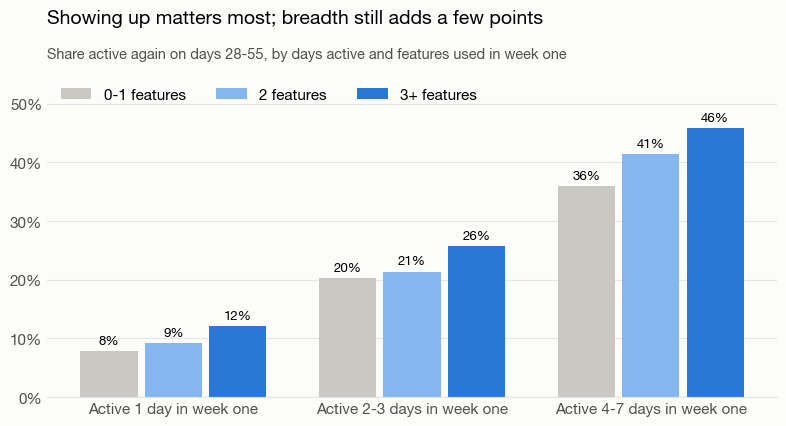

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.4))
width = 0.24
colours = [GREY, "#86b6ef", BLUE]
for i, (column, colour) in enumerate(zip(same_days.columns, colours)):
    x = [j + (i - 1) * (width + 0.03) for j in range(len(same_days))]
    bars = ax.bar(x, same_days[column], width=width, color=colour, label=column)
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in same_days[column]], padding=3, fontsize=9.5)
ax.set_xticks(range(len(same_days)), [f"Active {d} in week one" for d in same_days.index])
pct_axis(ax, 55)
ax.legend(frameon=False, ncols=3, loc="upper left")
title(ax, "Showing up matters most; breadth still adds a few points",
      "Share active again on days 28-55, by days active and features used in week one")
fig.tight_layout()
fig.savefig(IMG / "2_same_days.png", dpi=200)

Most of the gap is how many days people came back during week one: from about 8% for
one day to 36-46% for four or more. At the same number of days, trying three or more
features still adds 4 to 10 points over trying one. So breadth is a real but smaller
signal, and getting people to return on a second day is the bigger one.

## 4. Where do most new accounts stop?

In [11]:
def first_steps(features):
    features = [] if features is None else list(features)   # no features: an empty list comes back as None
    if features == ["Branches and repos"]:
        return "Created a repo, nothing else"
    if "Branches and repos" in features and "Push code" in features:
        return "Repo and pushed code" if len(features) == 2 else "Repo, code and one more"
    return "Other paths"


people["path"] = people["feature_list"].map(first_steps)
paths = (people.groupby("path")["came_back"].agg(accounts="size", came_back="mean")
         .assign(share_of_accounts=lambda d: (d["accounts"] / len(people) * 100).round(1),
                 came_back=lambda d: (d["came_back"] * 100).round(1))
         .loc[["Created a repo, nothing else", "Repo and pushed code",
               "Repo, code and one more", "Other paths"]])
paths

,accounts,came_back,share_of_accounts
path,,,
"Created a repo, nothing else",218023,8.6,34.8
Repo and pushed code,191904,16.4,30.6
"Repo, code and one more",37994,25.6,6.1
Other paths,178695,10.7,28.5


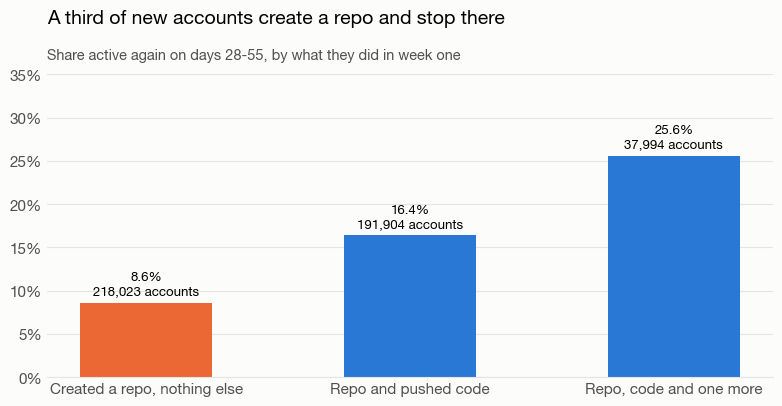

In [12]:
ladder = paths.drop("Other paths")
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(ladder.index, ladder["came_back"], width=0.5, color=[ORANGE, BLUE, BLUE])
ax.bar_label(bars, labels=[f"{v:.1f}%\n{n:,} accounts" for v, n in
                           zip(ladder["came_back"], ladder["accounts"])], padding=4, fontsize=9.5)
pct_axis(ax, 35)
title(ax, "A third of new accounts create a repo and stop there",
      "Share active again on days 28-55, by what they did in week one")
fig.tight_layout()
fig.savefig(IMG / "3_first_steps.png", dpi=200)

The biggest single group, 35% of new accounts, created a repository or branch and did
nothing else public that week. 8.6% of them came back. People who also pushed code
came back twice as often, and people who did one more thing on top did best.

## 5. Does it matter which third feature?

In [13]:
two_plus_one = people[people["path"] == "Repo, code and one more"].copy()
two_plus_one = two_plus_one[two_plus_one["features_week1"] == 3]
two_plus_one["third"] = two_plus_one["feature_list"].map(
    lambda fs: next(f for f in fs if f not in ("Branches and repos", "Push code")))
third = (two_plus_one.groupby("third")["came_back"].agg(accounts="size", came_back="mean")
         .query("accounts >= 1000")
         .assign(came_back=lambda d: (d["came_back"] * 100).round(1))
         .sort_values("accounts", ascending=False))
third

,accounts,came_back
third,,
Pull requests,10949,25.2
Stars,6705,23.8
Forks,4508,25.9
Collaborators,2549,25.7
Releases,1478,19.3
Issues,1302,18.2
Comments,1010,19.5


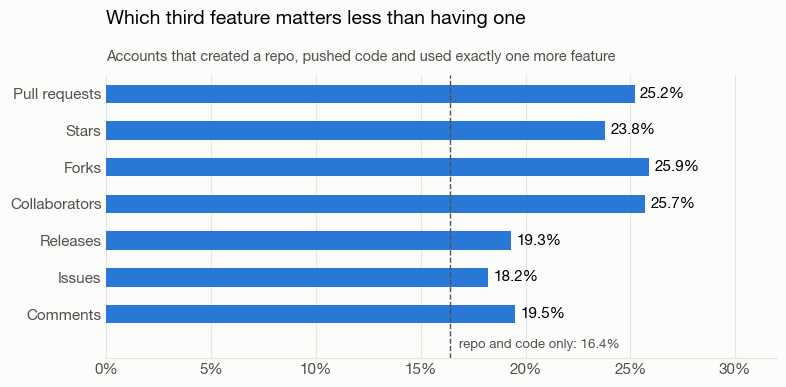

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ordered = third.sort_values("accounts")
bars = ax.barh(ordered.index, ordered["came_back"], height=0.5, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in ordered["came_back"]], padding=4)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 32)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
only_two = paths.loc["Repo and pushed code", "came_back"]
ax.axvline(only_two, color="#52514e", linestyle="--", linewidth=1)
ax.set_ylim(-1.2, len(ordered) - 0.5)
ax.text(only_two + 0.4, -0.85, f"repo and code only: {only_two:.1f}%",
        ha="left", va="center", fontsize=9.5, color="#52514e")
title(ax, "Which third feature matters less than having one",
      "Accounts that created a repo, pushed code and used exactly one more feature")
fig.tight_layout()
fig.savefig(IMG / "4_third_feature.png", dpi=200)

Every third feature beats stopping at repo and code (16.4%, the dashed line). Pull
requests, stars, forks and adding collaborators all land at 24-26%; issues, comments
and releases at 18-19%. None of them is a magic feature.

## What I'd recommend

Aim onboarding at the biggest group that stalls: people who create a repository and
do nothing else that week. Show them how to push their first commit right after the
repository is created, and send one reminder a day or two later. That aims at both
signals at once, a second feature and a second day.

This data shows who comes back, not what makes them come back, so I'd test it.

- **Who:** new accounts that created a repository and haven't pushed within 24 hours.
- **Control:** today's experience. **Treatment:** the first-push guide and a reminder.
- **Main metric:** active again on days 28-55. Today 8.6% for this group.
- **Also watch:** pushed code within week one.

How many accounts does the test need?

In [15]:
from math import sqrt

baseline, target = 0.086, 0.101          # a 1.5-point lift
z_alpha, z_power = 1.96, 0.84            # 5% significance, 80% power
per_group = (z_alpha + z_power) ** 2 * (baseline * (1 - baseline) + target * (1 - target)) \
    / (target - baseline) ** 2
weekly = paths.loc["Created a repo, nothing else", "accounts"] / 4
print(f"{per_group:,.0f} accounts per group; about {weekly:,.0f} such accounts sign up every week")

5,903 accounts per group; about 54,506 such accounts sign up every week


About 5,900 accounts per group, against roughly 54,000 new accounts a week that stop
after creating a repository. A week of sign-ups is enough, then two months of waiting
for the outcome.